## Project Framework (CRISP-DM)

### 1. Business Understanding
The goal of this project is to build a fast, automated system that classifies clients' banking requests by intent, minimizing the time it takes to route each request and give the client a correct answer.
- Faster routing reduces manual triage work for support teams.
- Accuracy matters: a misrouted request such as `compromised_card` delays a security issue, not just a reply.

### 2. Data Understanding
- 10,003 training and 3,080 test customer queries, 2 columns (`text`, `category`), 77 intent classes.
- The test set is balanced (40 queries per class); train class balance will be examined in EDA.
- No missing or empty values, no duplicate requests within either set.
- 6 near-duplicate queries shared between train and test (~0.2% of test), left as is due to negligible impact.
- Two inconsistent label names: `reverted_card_payment?` and `Refund_not_showing_up`.

### 3. Data Preparation
- Encode all 77 intent categories as integers.
- **MLP:** convert each query into a numeric vector using TF-IDF features.
- **RoBERTa:** tokenize queries into sub-word tokens, with padding and truncation to give every input the same length.

### 4. Modeling
- **Baseline:** Multi-Layer Perceptron on TF-IDF features. Fast and low-resource.
- **Advanced:** pre-trained RoBERTa transformer, fine-tuned with LoRA to adapt it to banking queries while training only a small fraction of its parameters.

### 5. Evaluation
- **Primary metric: Macro F1:** the average of per-class F1 scores, so all 77 intents count equally and weak performance on rarer intents can't hide behind common ones.
- **Secondary metrics:** accuracy, precision, recall.
- **Per-class comparison:** which intents improve most with RoBERTa, and which remain confused.
- **Efficiency:** training time and number of trainable parameters, to judge whether the extra complexity is justified.

### 6. Deployment
- Save the fine-tuned LoRA-RoBERTa model so it can be reused without retraining.
- Protect clients' sensitive data by redacting PII (card numbers, names, emails, phone numbers) before prediction.
- **Inference pipeline:** customer query → redact PII → predict intent → route to the right team.
- **Monitoring:** track live performance and data drift, and collect new labeled queries for retraining.

# Load and Verify Data

In [ ]:
import pandas as pd

df_train = pd.read_csv("datasets/banking77_train.csv")
df_test = pd.read_csv("datasets/banking77_test.csv")

def inspect_dataset(df, name):
    print(f"--- {name} ---")
    display(df.head())
    df.info()
    print(f"Number of missing values:\n{df.isna().sum()}")
    print(f"Number of empty texts: {df['text'].str.strip().eq('').sum()}")
    print(f"Number of duplicated texts: {df['text'].duplicated().sum()}")
    print(f"Number of unique categories: {df['category'].nunique()}")
    

inspect_dataset(df_train, "Train Dataset")
inspect_dataset(df_test, "Test Dataset")

print(f"--- Joint Tests ---")
print(f"Test labels unseen in train: {set(df_test['category']).difference(set(df_train['category']))}")
print(f"Number of shared texts: {len(set(df_train['text'].str.lower().str.strip()).intersection(set(df_test['text'].str.lower().str.strip())))}")

--- Train Dataset ---


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      10003 non-null  object
 1   category  10003 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB
Number of missing values:
text        0
category    0
dtype: int64
Number of empty texts: 0
Number of duplicated texts: 0
Number of unique categories: 77
--- Test Dataset ---


,text,category
0,How do I locate my card?,card_arrival
1,"I still have not received my new card, I order...",card_arrival
2,I ordered a card but it has not arrived. Help ...,card_arrival
3,Is there a way to know when my card will arrive?,card_arrival
4,My card has not arrived yet.,card_arrival


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3080 entries, 0 to 3079
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      3080 non-null   object
 1   category  3080 non-null   object
dtypes: object(2)
memory usage: 48.3+ KB
Number of missing values:
text        0
category    0
dtype: int64
Number of empty texts: 0
Number of duplicated texts: 0
Number of unique categories: 77
--- Joint Tests ---
Test labels unseen in train: set()
Number of shared texts: 6


### Data Quality Summary

| Check | Train | Test |
|---|---|---|
| Rows | 10,003 | 3,080 |
| Columns | `text`, `category` | `text`, `category` |
| Missing values | 0 | 0 |
| Empty / whitespace-only texts | 0 | 0 |
| Duplicate texts | 0 | 0 |
| Unique categories | 77 | 77 |

**Train vs. test:**
- All test categories are present in train, so there are no unseen labels.
- **0 exact** text overlaps; **6 near-duplicates** after lowercasing and stripping whitespace (~0.2% of test). Left untouched: the impact on evaluation is negligible, and the test set is kept unchanged as the benchmark.

**Observations:**
- Two labels have inconsistent naming: `reverted_card_payment?` (trailing `?`) and `Refund_not_showing_up` (capitalized). They are consistent across train and test, so they don't affect training, but they may be cleaned for readability in plots.
- The test set has exactly 40 queries per class (3,080 = 77 × 40). Train class balance will be examined in EDA.

**Conclusion:** both datasets load correctly and are clean, so they are ready for EDA.

# EDA

count     77.000000
mean     129.909091
std       32.942207
min       35.000000
25%      112.000000
50%      127.000000
75%      159.000000
max      187.000000
Name: count, dtype: float64
--- Class Maximums ---
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64
--- Class Minimums ---
category
get_disposable_virtual_card    97
top_up_limits                  97
receiving_money                95
atm_support                    87
compromised_card          

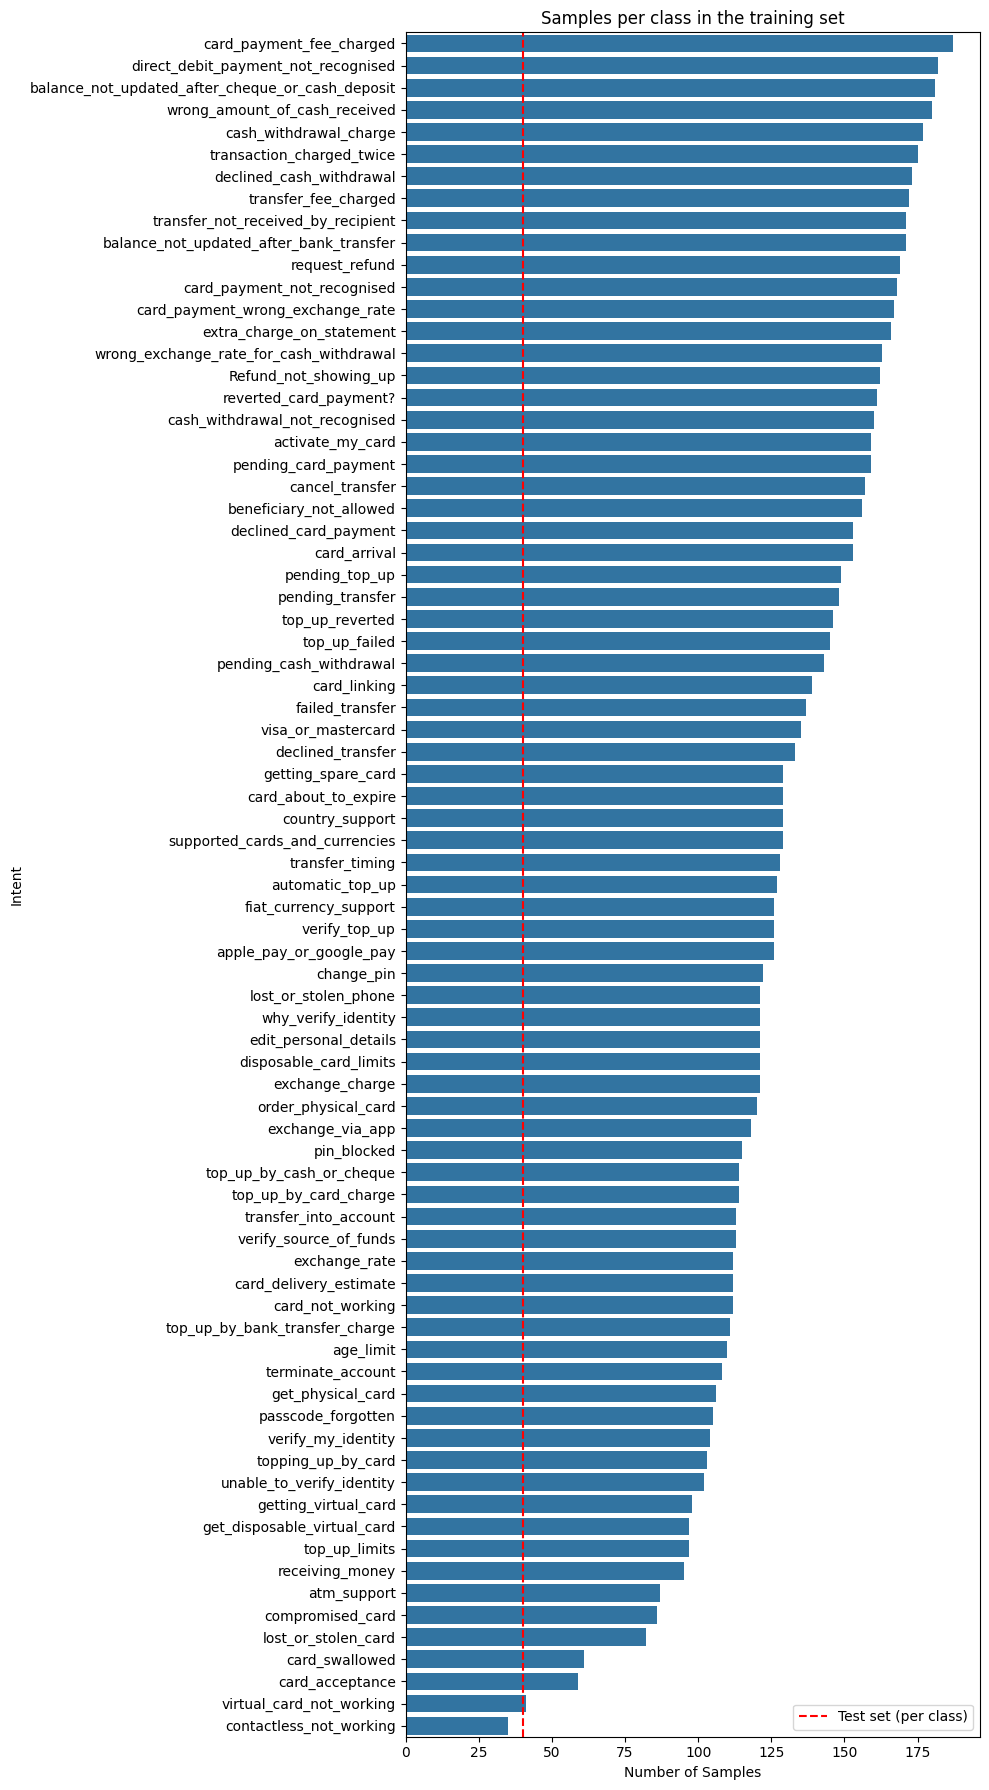

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

class_counts = df_train['category'].value_counts()
print(class_counts.describe())

class_maximums = class_counts.head(10)
class_minimums = class_counts.tail(10)
print(f"--- Class Maximums ---\n{class_maximums}")
print(f"--- Class Minimums ---\n{class_minimums}")

plt.figure(figsize=(10, 18))
sns.barplot(x=class_counts.values, y=class_counts.index)
plt.axvline(40, linestyle="--", color="red", label="Test set (per class)")
plt.title("Samples per class in the training set")
plt.xlabel("Number of Samples")
plt.legend()
plt.ylabel("Intent")
plt.tight_layout()
plt.show()

### Finding 1: Class distribution
- Moderate imbalance: 35–187 examples per class (median 127), a max/min ratio of about 5.3×.
- One class has fewer training than test examples: `contactless_not_working` (35 in train vs. 40 in test). Weaker scores are expected on this intent.
- 4 clear outliers: `card_swallowed`, `card_acceptance`, `virtual_card_not_working` and `contactless_not_working` (35–61). The other 73 classes decline smoothly from about 187 to about 82.
- Security-critical intents `compromised_card` and `lost_or_stolen_card` are in the bottom 7. The intents where a mistake costs the bank most are among the least represented, which supports Macro F1 as the primary metric.

count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: word_count, dtype: float64


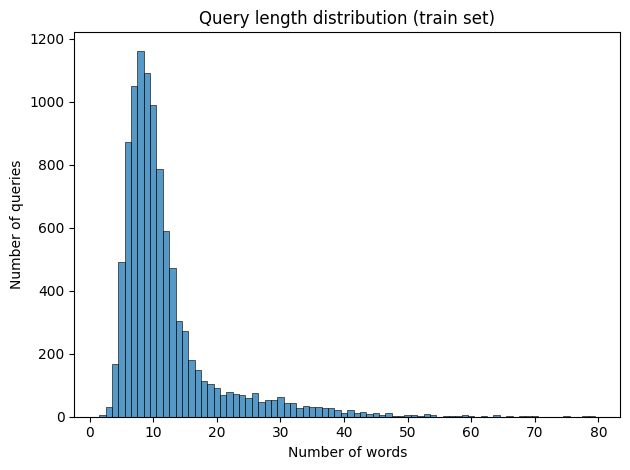

In [21]:
df_train['word_count'] = df_train['text'].str.split().str.len()
print(df_train['word_count'].describe())

sns.histplot(data=df_train, x="word_count", discrete=True)
plt.title("Query length distribution (train set)")
plt.xlabel("Number of words")
plt.ylabel("Number of queries")
plt.tight_layout()
plt.show()

In [26]:
print(df_train['word_count'].quantile([0.95, 0.99]))
three_or_less_words = df_train[df_train['word_count'] <= 3]
display(three_or_less_words[['text', 'category']])

0.95    29.0
0.99    43.0
Name: word_count, dtype: float64


,text,category
791,withdrawal pending meaning?,pending_cash_withdrawal
833,Explain pending transactions.,pending_cash_withdrawal
1513,Report stolen card,lost_or_stolen_card
2077,Cancel a transaction,cancel_transfer
2147,stop the transaction,cancel_transfer
2187,Cancel Transaction,cancel_transfer
2214,Cancelling a transaction,cancel_transfer
2235,Are top-ups unlimited?,top_up_limits
3233,top up cancellation,top_up_reverted
3293,Explain top-up cancellation,top_up_reverted


### Finding 2: Query length
- Median query length is 10 words (half of all queries have 7–13). The distribution is right-skewed: 95% of queries have ≤ 29 words and 99% have ≤ 43, with a max of 79.
- Implication for RoBERTa: a `max_length` of about 64 tokens should cover ~99% of queries without wasting computation on padding (to be confirmed with the tokenizer).
- Very short queries (≤ 3 words) are mostly clear, but some are near-identical across classes ("Explain pending transactions." → `pending_cash_withdrawal` vs. "pending transaction?" → `pending_card_payment`). Expect confusion between `pending_*` intents.
- Queries contain casing variants and typos (e.g. "Mastecard"). Lowercasing will help the TF-IDF baseline, while RoBERTa's sub-word tokenizer handles misspellings natively.

In [33]:
median_per_intent = df_train.groupby('category')['word_count'].median().sort_values(ascending=False)
head_median_per_intent = median_per_intent.head(5)
tail_median_per_intent = median_per_intent.tail(5)
print(f"--- Longest queries (median words) ---\n{head_median_per_intent}")
print(f"--- Shortest queries (median words) ---\n{tail_median_per_intent}")


--- Longest queries (median words) ---
category
balance_not_updated_after_cheque_or_cash_deposit    13.0
wrong_exchange_rate_for_cash_withdrawal             12.0
direct_debit_payment_not_recognised                 12.0
compromised_card                                    12.0
cash_withdrawal_not_recognised                      12.0
Name: word_count, dtype: float64
--- Shortest queries (median words) ---
category
top_up_limits          7.0
passcode_forgotten     7.0
order_physical_card    7.0
get_physical_card      7.0
exchange_rate          7.0
Name: word_count, dtype: float64


### Finding 3: Length by intent
- Median query length per intent ranges only from 7 to 13 words. Averages vary more (7.5–17.5) because a few intents have long tails of very detailed queries. Length alone barely separates intents.
- Length reflects the type of request: **problems and disputes** are longest (e.g. `balance_not_updated_after_cheque_or_cash_deposit`, `compromised_card`, ~12–13 words), while **simple questions and actions** are shortest (e.g. `top_up_limits`, `order_physical_card`, ~7 words).
- Implication: short queries rely on one or two keywords, so a typo or ambiguous word can easily flip the prediction. Longer problem queries are often the most urgent and the slowest for agents to read, so automated routing saves the most time there.

In [90]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = ENGLISH_STOP_WORDS.union({'im', 'dont', 'ive', 'cant', 'didnt', 'isnt', 'wont', 'havent', 'whats', 'doesnt', 'hasnt', 'wasnt', 'id'})

words = df_train[['category', 'text']].assign(word=df_train['text'].str.lower().str.replace(r'[^\w\s]', '', regex=True).str.split())
words = words.explode('word')
words = words[~words['word'].isin(stop_words)]
word_counts = words.groupby('category')['word'].value_counts()
top_words = word_counts.groupby(level=0).head(10)

# top_words.loc[['card_arrival', 'card_delivery_estimate']]
# top_words.loc[['pending_card_payment', 'pending_cash_withdrawal']]


### Finding 4: Vocabulary across intents
- **Shared topic words create overlap:** `card` + `delivery` appear in both `card_arrival` and `card_delivery_estimate`; `pending` is equally frequent in `pending_card_payment` and `pending_cash_withdrawal`.
- **Distinguishing keywords resolve it:** `track`/`sent`/`ordered` → `card_arrival` vs. `expect`/`soon`/`long` → `card_delivery_estimate`; `payment` → `pending_card_payment` vs. `cash`/`withdrawal`/`atm` → `pending_cash_withdrawal`.
- **Temporal language helps:** card intents differ by tense (past "it was sent, still waiting" vs. future "when will it arrive"), pending intents by time frame (duration "for days" vs. recent attempt "tried earlier").
- **Generic words create ambiguity:** `transaction` appears across pending intents. A query like "pending transaction?" has no distinguishing keyword, so it is hard to classify even for a human.
- Word variants (`track`/`tracking`, `delivery`/`delivered`) are counted separately. Stemming could merge them for the TF-IDF baseline.

# Preprocessing strategy
- **Labels (both models):** encode the 77 intents as integers 0–76 with `LabelEncoder`, fitted on train and applied unchanged to test, so both models share the same mapping.
- **MLP baseline:** clean the `text` column by lowercasing and removing punctuation. Stopwords are kept so negations ("not", "haven't") aren't lost; TF-IDF down-weights common words automatically. Then vectorize with TF-IDF, fitted on train only to avoid data leakage. Typos remain a known weakness of this word-level approach.
- **RoBERTa:** no text cleaning. The model was pre-trained on raw text, so casing, punctuation and stopwords carry useful signal. Tokenize with RoBERTa's own sub-word tokenizer, padding/truncating to `max_length` ≈ 64 tokens (based on 99% of queries having ≤ 43 words), which produces `input_ids` and an `attention_mask`.

# MLP: Model

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from torch.utils.data import Dataset, DataLoader
import torch

torch.manual_seed(42)

label_encoder = LabelEncoder()
labels_train = label_encoder.fit_transform(df_train['category'])
labels_test = label_encoder.transform(df_test['category'])

vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)
text_train = vectorizer.fit_transform(df_train['text'])
text_test = vectorizer.transform(df_test['text'])

class BankingDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        text = torch.tensor(self.texts[index].toarray()[0], dtype=torch.float32)
        label = torch.tensor(self.labels[index], dtype=torch.long)  
        return text, label

banking_train_dataset = BankingDataset(text_train, labels_train)
banking_test_dataset = BankingDataset(text_test, labels_test)
banking_train_loader = DataLoader(banking_train_dataset, batch_size=32, shuffle=True)
banking_test_loader = DataLoader(banking_test_dataset, batch_size=32, shuffle=False)

torch.Size([32, 10292]) torch.float32 torch.Size([32]) torch.int64


### MLP model notes
- labels: `LabelEncoder`, 77 classes, fitted on train
- TF-IDF: unigrams + bigrams, `min_df=2` → 10,292 features; stopwords kept (negations); the default token pattern handles punctuation
- DataLoaders: batch size 32, train shuffled, test not